> ### Note on Labs and Assigments:
>
> 🔧 Look for the **wrench emoji** 🔧 — it highlights where you're expected to take action, write code (use AI as you need but cleanup the code)!

> These sections are graded and are not optional.
>

# **IS 4487 Assignment 7: Data Transformation with Airbnb Listings**

In this assignment, you will:
- Load the Airbnb dataset you cleaned in Assignment 6
- Apply data transformation techniques like scaling, binning, encoding, and feature creation
- Make the dataset easier to use for tasks like pricing analysis, guest segmentation, or listing recommendations
- Practice writing up your analysis clearly so a business audience — like a host, marketing manager, or city partner — could understand it

## Why This Matters

Airbnb analysts, hosts, and city partners rely on clean and well-structured data to make smart decisions. Whether they’re adjusting prices, identifying high-performing listings, or designing better guest experiences, they need data that’s transformed, organized, and ready for use.

This assignment helps you practice that kind of real-world thinking: taking messy real data and getting it ready for action.

<a href="https://colab.research.google.com/github/vandanara/UofUtah_IS4487/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

## **Task 1. Setup and Load Your Data**

1.1. Import the libraries you'll need for this assignment:
- `pandas`, `numpy` for data manipulation
- `matplotlib.pyplot`, `seaborn` for visualizations

You'll be working with the `cleaned_airbnb_data.csv` file you exported from Assignment 6.

1.2 In Google Colab:
- Click the folder icon on the left sidebar
- Use the upload button to add your CSV file to the session
- Then write code below to read it into your notebook



In [2]:
# 🔧 1.1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 🔧 1.2. Import saved dataset
df = pd.read_csv("/content/cleaned_airbnb_data.csv")
print(df.shape)
df.head()

(6748, 86)


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,14842,https://www.airbnb.com/rooms/14842,20260917204825,2026-09-20,NaN,Portobello Gem. Entire house. Can sleep 4.,Beautiful entire house with superfast broadban...,NaN,https://a0.muscache.com/pictures/106656330/fa1...,58344,...,4.82,4.91,4.91,4.62,NaN,1,1,0,0,0.25
1,44077,https://www.airbnb.com/rooms/44077,20260917204825,2026-09-20,NaN,cosy comfortable Irish cottage twin,Our house is a cosy comfortable cottage with ...,NaN,https://a0.muscache.com/pictures/525706/050a3a...,193005,...,4.94,4.94,4.69,4.83,NaN,2,0,2,0,2.19
2,85156,https://www.airbnb.com/rooms/85156,20260917204825,2026-09-20,NaN,Cosy Comfortable Irish Cottage 1 Double Bed,Our Cottage is a charming light filled cottage...,NaN,https://a0.muscache.com/pictures/1749253/9ed2a...,193005,...,4.91,4.89,4.65,4.77,NaN,2,0,2,0,2.01
3,159889,https://www.airbnb.com/rooms/159889,20260917204825,2026-09-20,NaN,Friendly Single Room,Washing can be done at a cost of €5 per load....,NaN,https://a0.muscache.com/pictures/3031697/a8259...,766611,...,4.83,4.87,4.66,4.72,NaN,3,0,3,0,2.88
4,162809,https://www.airbnb.com/rooms/162809,20260917204825,2026-09-20,previous scrape,5.5 miles south of Dublin City :^),A nice place to relax after the bustle of the ...,NaN,https://a0.muscache.com/pictures/86694529/c07b...,777681,...,4.94,4.97,4.79,4.86,NaN,2,0,2,0,3.21


## **Task 2. Check for Skew in a Numeric Column**

Business framing:  

Airbnb listings can have a wide range of values for things like price, availability, or reviews. These kinds of distributions can be hard to visualize, summarize, or model.

Choose one **numeric column** that appears skewed and do the following:

2.1. Plot a histogram

2.2. Apply a transformation (e.g., log or other method)

2.3. Plot again to compare



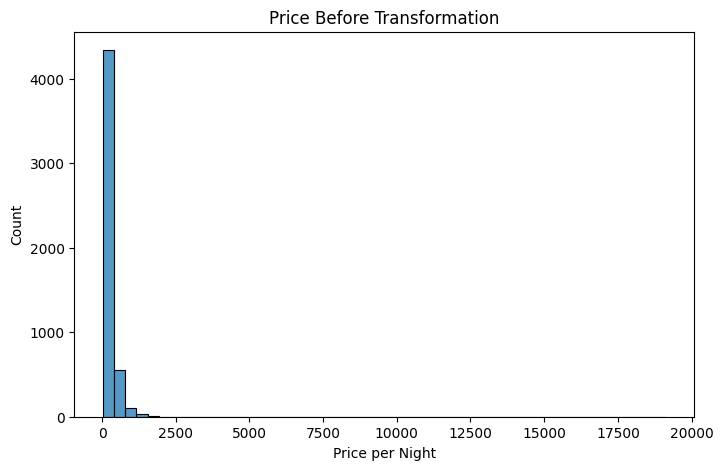

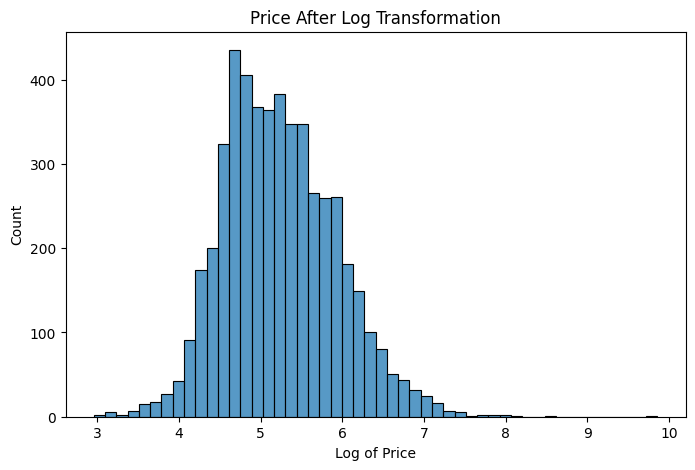

In [3]:
# 🔧 2.1. Add code here - show before histogram
plt.figure(figsize=(8, 5))
sns.histplot(df['price'].dropna(), bins=50)
plt.title('Price Before Transformation')
plt.xlabel('Price per Night')
plt.show()

# 🔧 2.2. Add code here
df['price_log'] = np.log1p(df['price'])

# 🔧 2.3. Add code here - show after histogram
plt.figure(figsize=(8, 5))
sns.histplot(df['price_log'].dropna(), bins=50)
plt.title('Price After Log Transformation')
plt.xlabel('Log of Price')
plt.show()

### ✍️ Please answer the following:

2.4. What column did you examine?

2.5. What transformation did you try, and why?

2.6. How did the transformed version help make the data more usable for analysis or stakeholder review?

### ✍️ Your Response:

2.4. I looked at the price column.

2.5. I used the log transformation because I saw that the price is very skewed. Most of the listings cost under $300 a night, but the highest is $19,140.

2.6. After the transformation, the prices are spread out more evenly and are easier to read in a chart. The extreme prices don't squish everything else to one side.

## **Task 3. Scale Two Numeric Columns**

Business framing:

If an analyst wanted to compare listing price to number of nights required, or create a model that weighs both, those values need to be on a similar scale.

Follow these steps:
Pick two numeric columns with different value ranges (e.g. one column may have a min of 0 and a max of 255; another column may have a min of 100 and a max of 400). Apply two different types of scaling to them, and add these 2 new columns to the dataset with colnames ending in "_std" or "_norm"

3.1. Use Min-Max normalization on one column (range shoudl be 0-1)

3.2. Use Z-score standardization on the other column (mean should be 0 and var = 1)


3.3. Use .describe() to view the newly created variables before and after transformation.

In [4]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# 🔧 3.1. Min-Max normalization
minmax = MinMaxScaler()
df['accommodates_norm'] = minmax.fit_transform(df[['accommodates']])

# 🔧 3.2. Z-score standardization
standard = StandardScaler()
df['availability_365_std'] = standard.fit_transform(df[['availability_365']])

# 🔧 3.3 view the before and after variables
df[['accommodates', 'accommodates_norm', 'availability_365', 'availability_365_std']].describe()

,accommodates,accommodates_norm,availability_365,availability_365_std
count,6748.000000,6748.000000,6748.000000,6.748000e+03
mean,3.324392,0.154959,146.848400,-5.054246e-17
std,2.135852,0.142390,131.726688,1.000074e+00
min,1.000000,0.000000,0.000000,-1.114879e+00
25%,2.000000,0.066667,7.000000,-1.061734e+00
50%,2.000000,0.066667,116.000000,-2.342022e-01
75%,4.000000,0.200000,269.000000,9.273797e-01
max,16.000000,1.000000,365.000000,1.656215e+00


### ✍️ Please answer the following:

3.4. What two columns did you scale, and which methods did you use?

3.5. When might these scaled values be more useful than the originals?

3.6. Who at Airbnb might benefit from this transformation and why?

### ✍️ Your Response: 🔧

3.4. I used Min-Max on accommodates so it goes from 0 to 1. I used Z-score on availability_365 so the mean is 0.

3.5. They might be more useful when you compare or combine the columns. Without them, availability looks more important just because its numbers are bigger.

3.6. Airbnb analysts could use this transformation to build fairer pricing models and compare listings more easily.



```
# This is formatted as code
```

## **Task 4. Bin a Numeric Column into Categories**

Business framing:  

Let’s say an Airbnb marketing team wants to segment listings by review activity. They don’t want exact numbers — they just want to know if a listing has “low,” “medium,” or “high” review volume.

4.1. Follow these steps:

- Choose a numeric column that could be grouped (e.g., reviews, availability).
- You’ll want to group the values of this column into 3 or 4 bins
- Create a new column. The values of this column will be the labels: “Low”, “Medium”, and “High.” These labels should correspond to your bins.

4.2. Output/view this column before and after transformation.



In [5]:
# 🔧 4.1. Add code here
df['review_level'] = pd.cut(df['number_of_reviews'],
                            bins=[-1, 10, 50, df['number_of_reviews'].max()],
                            labels=['Low', 'Medium', 'High'])

# 🔧 4.2. Add code here
print(df[['number_of_reviews', 'review_level']].head(10))
print(df['review_level'].value_counts())

   number_of_reviews review_level
0                 46       Medium
1                414         High
2                376         High
3                509         High
4                442         High
5                660         High
6                 10          Low
7                559         High
8                 82         High
9                198         High
review_level
Low       2853
Medium    1977
High      1918
Name: count, dtype: int64


### ✍️ Please answer the following:

4.3. What column did you group, and how many categories did you use?

4.4. Why might someone prefer this grouped view over raw numbers?

4.5. Who would this help at Airbnb, and how?

### ✍️ Your Response: 🔧

4.3.

4.4.

4.5.

## **Task 5. Create Two New Business-Relevant Variables**

Business framing:  

Stakeholders often want to know things like: What’s the cost per night? Are listings geared toward long-term stays? These kinds of features aren’t always in the dataset — analysts create them.

Follow these steps:

5.1. - 5.2. Add two new columns to your DataFrame.
- Think of two new columns you can create or calculate using the data you already have.
  - One might be a ratio or interaction between columns (e.g., price ÷ nights).
  - The other might be a flag based on a condition (e.g., stays longer than 30 days).

5.3. View these new columns using .describe()



In [ ]:
# 🔧 5.1. Add code here


# 🔧 5.2. Add code here


# 🔧 5.3. Add code here



 ### ✍️ Please answer the following:

5.4. What two new columns did you create?

5.5. Who would use them (e.g., host, manager, or platform)?

5.6. How could they help someone make a better decision?


### ✍️ Your Response:

5.4.

5.5.

5.6.



## **Task 6. Encode a Categorical Column**

Business framing:  

Let’s say you’re helping the Airbnb data science team build a model to predict booking rates. Categorical columns like `room_type`, `neighbourhood`, or `cancellation_policy` can’t be used in models unless they’re converted to numbers.

6.1. Do the following:
- Choose one categorical column from your dataset (e.g., room type or neighborhood group)
- Decide on an encoding method:
  - Use one-hot encoding for nominal (unordered) categories
  - Use ordinal encoding (a ranking) only if the categories have a clear order
- Apply the encoding
- Add the new encoded column(s) to your DataFrame

6.2. Display the encodings - the new variables.





In [ ]:
# 🔧 6.1. Add code here

# 🔧 6.2. Add code here



### ✍️ Please answer the following:

6.3. What column did you encode and why?

6.4. What encoding method did you use?

6.5. How could this transformation help a pricing model, dashboard, or business report?

### ✍️ Your Response: 🔧

6.3.

6.4.

6.5.

## **Task 7. Reflection**

You’ve applied the same kinds of transformation techniques used in real Airbnb analytics projects — from pricing engines to host tools to tourism dashboards.

Now step back and reflect.

### ✍️ Please answer the following:

7.1. What transformation step felt most important or interesting?

7.2. Which of your changes would be most useful to a host, analyst, or city planner?

7.3. If you were going to build a tool or dashboard, what would you do next with this data?

7.4. How does this relate to your customized learning outcome you created in canvas?



### ✍️ Your Response: 🔧

7.1.

7.2.

7.3.

7.4.



## **Task 8. Export Cleaned Data**

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 11**, where you'll use the data in a regression model.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_7.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```

In [ ]:
# 🔧export csv here

## Submission Instructions
✅ Checklist:
- Make sure all code cells are run and outputs are visible  
- All markdown/comment questions are answered thoughtfully  
- Save the file with your last name and first name as shown below (see detailed instructions in Lab 1 on how to do this).
- Submit the assignment as an **HTML file** on Canvas

In [ ]:
!jupyter nbconvert --to html "assignment_07_LastnameFirstname.ipynb"